# PINNs for Mechanical Engineers — Tutorial 6: Transient Backward-Facing Step
### Ten seconds of pulsating flow, one window at a time

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

Tutorials 1–5 solved **steady** problems: nothing changed with time. This one adds the fourth coordinate — and then pushes it far enough that the standard approach breaks, forcing us to solve time the way a CFD code does: **marching**.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | ✅ |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | ✅ |
| 6 | Backward-Facing Step | flow separation & reattachment | ✅ |
| **7** | **Transient Backward-Facing Step** | **time-dependent flow, time-windowed training** | **📍 You are here** |

Every tutorial is standalone and validated against a reference solution —
analytical where one exists, a published benchmark otherwise — with real
training logs. No hand-waving.

> **New to PINNs?** This series assumes you're already comfortable with the
> fundamentals: autograd, collocation points, the residual loss, the
> Adam → L-BFGS recipe. If you're starting from zero — or you just want the
> deeper, build-it-from-scratch treatment in one place — I wrote a 100+ page
> ebook that does exactly that: from your very first autograd call through 1D
> ODEs, the Poisson equation, and nonlinear Burgers. It's the foundation this
> series builds on.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **unsteady incompressible Navier–Stokes equations** with a PINN — time as a **third network input**, and $\partial u/\partial t$ terms in the residual
- Driven the flow with a **pulsatile inlet**, $\bar u(t)=1+A\sin(\omega t)$, and watched the **recirculation bubble breathe** as the reattachment length oscillates through every cycle
- Discovered why a single network **fails over long horizons** — PINNs optimize all times at once and quietly violate causality
- Fixed it with **time-windowed training**: a sequence of short windows, each warm-started from the last and each inheriting its initial condition from its predecessor — a PINN that marches through time like a CFD solver
- Simulated a full **10 seconds (ten pulsation cycles)** and animated it as **GIFs that play inline**
- Learned the deepest lesson about unsteady PINNs: **driven unsteadiness converges; self-excited unsteadiness does not** — which is exactly why a pulsating inlet works where vortex shedding famously fails

**Prerequisites:** the steady backward-facing step. The geometry, walls, and Navier–Stokes machinery are unchanged — what's new is time, and how to march through it.

---

## 2 — The problem: what changes when time enters

The geometry, walls, and Reynolds number are exactly as in the steady tutorial. Two things change.

### 1. The equations gain time derivatives

$$
\begin{aligned}
\frac{\partial u}{\partial t} + u\,u_x + v\,u_y &= -p_x + \tfrac{1}{Re}(u_{xx}+u_{yy}) \\
\frac{\partial v}{\partial t} + u\,v_x + v\,v_y &= -p_y + \tfrac{1}{Re}(v_{xx}+v_{yy}) \\
u_x + v_y &= 0
\end{aligned}
$$

Continuity is unchanged (incompressibility is instantaneous), but both momentum equations now carry $\partial/\partial t$. In the network this costs almost nothing: $t$ becomes a third input, and $u_t$ is just another autograd slice.

### 2. The inlet pulsates, and we need an initial condition

The inlet keeps its parabolic shape while its amplitude oscillates:

$$u_{\text{in}}(y,t)=6(y-s)(H-y)\big[1+A\sin(\omega t)\big]$$

with $A=0.5$ and period $\mathcal T=1$, so the mean inlet velocity swings between 0.5 and 1.5. A time-dependent problem also needs an **initial condition**: at $t=0$ the fluid is **at rest**.

### Why this converges (and vortex shedding doesn't)

This is the honest heart of the tutorial. A forward PINN minimizes the residual over the whole space–time domain at once, so it is strongly pulled toward the *simplest* solution consistent with the constraints — usually a **steady** one. For flow past a cylinder, the steady symmetric wake *is* a valid solution, so the network collapses onto it and the vortex street never appears.

Here it can't. The unsteadiness is **forced by the boundary condition** — the inlet literally demands different values at different $t$. No time-independent field can satisfy a time-varying inlet, so the network is compelled to learn genuine time dependence.

**The rule: *driven* unsteadiness converges; *self-excited* unsteadiness (instabilities, shedding) does not.**

## 3 — Imports and setup

The new constants are temporal: the horizon, the pulsation, and the **window length** that will let us march through ten seconds.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# geometry (unchanged from the steady tutorial)
Li=3.0; Lo=14.0; h=1.0; s=1.0; H=2.0
RE = 100.0                     # Re_s = u_bar*s/nu  (Re_Dh = 200: laminar)

# time
T_PERIOD = 1.0                 # pulsation period
T_END    = 10.0                # ten full cycles
AMP      = 0.5                 # mean inlet velocity swings 0.5 .. 1.5
OMEGA    = 2*math.pi/T_PERIOD

# time-windowing: one window per period
W_LEN     = 1.0
N_WINDOWS = int(round(T_END/W_LEN))

FULL_TRAINING = device.type == 'cuda'
N_f = 6000 if FULL_TRAINING else 800     # interior points PER WINDOW
N_b = 400  if FULL_TRAINING else 80      # per boundary segment, per window
N_0 = 800  if FULL_TRAINING else 150     # initial-condition points per window
ADAM_PER_WINDOW  = 1500 if FULL_TRAINING else 15
LBFGS_PER_WINDOW = 800  if FULL_TRAINING else 5

print(f"Transient BFS | Re_s={RE:g} | horizon={T_END} = {N_WINDOWS} windows of {W_LEN}")
print(f"per window: interior={N_f}, boundary={N_b}/segment, IC={N_0}")

Using device: cuda
GPU: Tesla T4
Transient BFS | Re_s=100 | horizon=10.0 = 10 windows of 1.0
per window: interior=6000, boundary=400/segment, IC=800


## 4 — Reference quantities

The pulsatile inlet and the domain mask. The inlet now depends on **both** $y$ and $t$.

In [2]:
def inlet_velocity(y, t):
    "Pulsatile parabolic inlet: shape in y, amplitude oscillating in t."
    return 6.0*(y-s)*(H-y)*(1.0 + AMP*torch.sin(OMEGA*t))

def inside_fluid(x, y):
    "Boolean mask for the L-shaped fluid domain."
    return ((x>=-Li)&(x<=0)&(y>=s)&(y<=H)) | ((x>=0)&(x<=Lo)&(y>=0)&(y<=H))

y_ref = torch.linspace(s,H,501,device=device).reshape(-1,1)
u_pk  = inlet_velocity(y_ref, torch.full_like(y_ref, T_PERIOD/4))   # peak of the cycle
print(f"inlet walls: u={u_pk[0].item():.4f}, {u_pk[-1].item():.4f}  (want 0, 0)")
print(f"peak inlet max: {u_pk.max().item():.4f}  (want {1.5*(1+AMP):.2f})")
for tv in [0.0,0.25,0.5,0.75]:
    print(f"  t={tv:.2f}  mean inlet velocity = {1+AMP*math.sin(OMEGA*tv):.3f}")

inlet walls: u=0.0000, 0.0000  (want 0, 0)
peak inlet max: 2.2500  (want 2.25)
  t=0.00  mean inlet velocity = 1.000
  t=0.25  mean inlet velocity = 1.500
  t=0.50  mean inlet velocity = 1.000
  t=0.75  mean inlet velocity = 0.500


## 5 — The network

One change from the steady version: **three inputs** $(x,y,t)$. Outputs are still $(u,v,p)$.

The input normalisation deserves a note. Each window covers a *different* slice of time, so `lb`/`ub` are set **per window** — every window's network sees its own time interval mapped to $[-1,1]$, which keeps the inputs well-scaled no matter how far along the horizon we are.

In [3]:
class PINN(nn.Module):
    "Input (x,y,t) -> outputs (u,v,p). Time bounds are set per window."
    def __init__(self, t0=0.0, t1=W_LEN, n_hidden=64, n_layers=6):
        super().__init__()
        layers = [nn.Linear(3,n_hidden), nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden,3)]
        self.net = nn.Sequential(*layers)
        self.register_buffer('lb', torch.tensor([-Li,0.0,t0]))
        self.register_buffer('ub', torch.tensor([ Lo,H,  t1]))
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, xyt):
        z = 2.0*(xyt-self.lb)/(self.ub-self.lb) - 1.0
        return self.net(z)

model = PINN().to(device)
print(f"Trainable parameters per window: {sum(p.numel() for p in model.parameters())}")

Trainable parameters per window: 21251


## 6 — Fields and automatic differentiation

In [4]:
def fields(xyt):
    "Network fields u(x,y,t), v(x,y,t), p(x,y,t)."
    out = model(xyt)
    return out[:,0:1], out[:,1:2], out[:,2:3]

def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True,retain_graph=True)[0]

probe = torch.rand(8,3,device=device)*torch.tensor([1.,1.,W_LEN],device=device)
u0,v0,p0 = fields(probe)
print(f"u {tuple(u0.shape)} | v {tuple(v0.shape)} | p {tuple(p0.shape)}")

u (8, 1) | v (8, 1) | p (8, 1)


## 7 — The residual: now with time derivatives

The only change from the steady residual is $u_t$ and $v_t$. Because $t$ is the third input column, `grad(u,xyt)[:,2:3]` **is** $\partial u/\partial t$ — no new machinery at all.

In [5]:
def residuals(xyt, Re):
    "Unsteady x-momentum, y-momentum, and continuity residuals."
    u,v,p = fields(xyt)
    gu = grad(u,xyt); gv = grad(v,xyt); gp = grad(p,xyt)
    u_x,u_y,u_t = gu[:,0:1], gu[:,1:2], gu[:,2:3]      # <- time derivative
    v_x,v_y,v_t = gv[:,0:1], gv[:,1:2], gv[:,2:3]      # <- time derivative
    p_x,p_y     = gp[:,0:1], gp[:,1:2]
    u_xx = grad(u_x,xyt)[:,0:1]; u_yy = grad(u_y,xyt)[:,1:2]
    v_xx = grad(v_x,xyt)[:,0:1]; v_yy = grad(v_y,xyt)[:,1:2]
    r_x = u_t + u*u_x + v*u_y + p_x - (u_xx+u_yy)/Re
    r_y = v_t + u*v_x + v*v_y + p_y - (v_xx+v_yy)/Re
    r_c = u_x + v_y
    return r_x, r_y, r_c

## 8 — Why a single network fails over 10 seconds

The obvious approach is to set `T_END = 10` and train one network on the whole space–time slab. **It does not work well**, for two reasons:

1. **The domain grows.** Ten times the horizon with the same point budget means ten times sparser coverage in $t$.
2. **PINNs violate causality.** They optimize *all times simultaneously* — the network has no notion that $t=1$ must settle before $t=9$. Over a long horizon it fits the easy early times and smears the late ones, and you watch the oscillation amplitude decay along $t$ as the flow "forgets" to pulse.

### The fix: march through time

**Time-windowing** solves a short window, then hands its end state to the next as an initial condition — exactly how a CFD code time-steps.

$$[0,1] \;\longrightarrow\; [1,2] \;\longrightarrow\; [2,3] \;\longrightarrow\;\cdots\;\longrightarrow\; [9,10]$$

Three things make this work:

- **Causality by construction.** Window $k$ cannot be influenced by window $k{+}1$; time only flows forward.
- **Every window is an easy problem** — one period, the size we already know converges.
- **Warm starting.** Each window inherits the previous window's weights, so later windows start from a network that already understands the flow. In practice they converge *faster* and to *lower* loss than the first.

The handoff is the whole trick: window $k{+}1$'s initial condition is window $k$'s solution evaluated at the shared boundary time.

## 9 — Sampling one window

Collocation, boundary, and initial-condition points — all confined to a single window $[t_0,t_1]$.

In [6]:
gen = torch.Generator().manual_seed(42)
def rb(a,b,n): return (a+(b-a)*torch.rand(n,1,generator=gen)).to(device)

def sample_xy(n):
    "Spatial points, weighted toward the region behind the step."
    n1=int(0.3*n); n2=n-n1
    pre  = torch.cat([rb(-Li,0,n1), rb(s,H,n1)],1)
    post = torch.cat([rb(0,Lo,n2),  rb(0,H,n2)],1)
    return torch.cat([pre,post],0)

def sample_window(t0, t1):
    "All point sets for the window [t0, t1]."
    xy  = sample_xy(N_f)
    f   = torch.cat([xy, rb(t0,t1,xy.shape[0])],1).requires_grad_(True)
    inl = torch.cat([-Li*torch.ones(N_b,1,device=device), rb(s,H,N_b), rb(t0,t1,N_b)],1)
    out = torch.cat([ Lo*torch.ones(N_b,1,device=device), rb(0,H,N_b), rb(t0,t1,N_b)],1).requires_grad_(True)
    def wall(xs,ys): return torch.cat([xs,ys,rb(t0,t1,N_b)],1)
    wl = torch.cat([wall(rb(-Li,Lo,N_b), H*torch.ones(N_b,1,device=device)),
                    wall(rb(-Li,0,N_b),  s*torch.ones(N_b,1,device=device)),
                    wall(torch.zeros(N_b,1,device=device), rb(0,s,N_b)),
                    wall(rb(0,Lo,N_b),   torch.zeros(N_b,1,device=device))],0)
    xy0 = sample_xy(N_0)
    ic  = torch.cat([xy0, torch.full((xy0.shape[0],1), t0, device=device)],1)
    return f, inl, out, wl, ic

xyt_f, xyt_in, xyt_out, xyt_wall, xyt_0 = sample_window(0.0, W_LEN)
IC_U = torch.zeros(xyt_0.shape[0],1,device=device)     # first window: fluid at rest
IC_V = torch.zeros(xyt_0.shape[0],1,device=device)
print(f"per window -> interior {xyt_f.shape[0]}, inlet {xyt_in.shape[0]}, "
      f"outlet {xyt_out.shape[0]}, walls {xyt_wall.shape[0]}, IC {xyt_0.shape[0]}")

per window -> interior 6000, inlet 400, outlet 400, walls 1600, IC 800


## 10 — The loss

Five terms. The initial-condition term is the one that carries the march: for the first window it enforces **fluid at rest**; for every later window it enforces **continuity with the previous window's final state**.

In [7]:
W_INLET=10.0; W_WALL=10.0; W_OUTLET=1.0; W_IC=10.0
def mse(z): return (z**2).mean()

def compute_losses(Re):
    r_x,r_y,r_c = residuals(xyt_f,Re)
    loss_pde = mse(r_x)+mse(r_y)+mse(r_c)

    u_i,v_i,_ = fields(xyt_in)                                  # pulsatile inlet
    loss_in   = mse(u_i-inlet_velocity(xyt_in[:,1:2],xyt_in[:,2:3]))+mse(v_i)

    u_w,v_w,_ = fields(xyt_wall)                                # no-slip, all times
    loss_wall = mse(u_w)+mse(v_w)

    u_o,v_o,p_o = fields(xyt_out)                               # outflow + gauge
    loss_out = mse(grad(u_o,xyt_out)[:,0:1])+mse(grad(v_o,xyt_out)[:,0:1])+mse(p_o)

    u_0,v_0,_ = fields(xyt_0)                                   # handoff from prev window
    loss_ic  = mse(u_0-IC_U)+mse(v_0-IC_V)
    return loss_pde, loss_in, loss_wall, loss_out, loss_ic

def total_loss(Re):
    lp,li,lw,lo,lic = compute_losses(Re)
    return lp + W_INLET*li + W_WALL*lw + W_OUTLET*lo + W_IC*lic

lp,li,lw,lo,lic = compute_losses(RE)
print(f"untrained: pde={lp.item():.3e} inlet={li.item():.3e} wall={lw.item():.3e} "
      f"out={lo.item():.3e} ic={lic.item():.3e}")

untrained: pde=2.461e-02 inlet=1.557e+00 wall=5.208e-02 out=1.736e-03 ic=4.732e-02


## 11 — The key diagnostic: is the solution actually time-dependent?

The check that matters most. A forward PINN on an unsteady problem can silently converge to a **time-averaged steady field** — the loss falls, the plots look plausible, and the physics is wrong.

So measure it: sample the same spatial point at several phases within a window and compute the **spread** of the velocity. A healthy unsteady solution has spread well above zero; a collapsed one drifts toward zero.

In [8]:
@torch.no_grad()
def time_variation(t0, t1, x_probe=2.0):
    "Spread of u across phases inside a window: >0 means genuinely unsteady."
    ys = torch.linspace(0,H,40,device=device).reshape(-1,1)
    xs = torch.full_like(ys, x_probe)
    us = [fields(torch.cat([xs,ys,torch.full_like(ys, t0+f*(t1-t0))],1))[0]
          for f in (0.25,0.5,0.75)]
    return torch.stack(us).std(0).mean().item()

print(f"time-variation (untrained): {time_variation(0.0,W_LEN):.3e}")

time-variation (untrained): 1.869e-02


## 12 — Marching through ten seconds

Now the march. For each window: build a fresh network (warm-started from the previous one), sample the window, take the initial condition from the previous window's solution, and train Adam → L-BFGS.

Watch two things in the log: the losses should **fall from window to window** (warm starting compounds), and `timevar` should stay comfortably above zero — the flow keeping its heartbeat all the way to $t=10$.

In [9]:
def make_window_model(t0, t1, prev=None):
    "Fresh model for [t0,t1], warm-started from the previous window."
    m = PINN(t0, t1).to(device)
    if prev is not None:
        m.load_state_dict(prev.state_dict(), strict=False)      # inherit weights
        m.lb.copy_(torch.tensor([-Li,0.0,t0], device=device))   # but re-scale time
        m.ub.copy_(torch.tensor([ Lo,H,  t1], device=device))
    return m

window_models = []
history = {"win":[], "t0":[], "pde":[], "inlet":[], "wall":[], "ic":[], "timevar":[]}
prev = None

for k in range(N_WINDOWS):
    t0, t1 = k*W_LEN, (k+1)*W_LEN
    tic = time.time()

    model = make_window_model(t0, t1, prev)
    xyt_f, xyt_in, xyt_out, xyt_wall, xyt_0 = sample_window(t0, t1)

    # initial condition: previous window's field at t0 (rest for the first window)
    if prev is None:
        IC_U = torch.zeros(xyt_0.shape[0],1,device=device)
        IC_V = torch.zeros(xyt_0.shape[0],1,device=device)
    else:
        with torch.no_grad():
            o = prev(xyt_0); IC_U, IC_V = o[:,0:1].clone(), o[:,1:2].clone()

    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for i in range(ADAM_PER_WINDOW):
        opt.zero_grad(); total_loss(RE).backward(); opt.step()

    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_PER_WINDOW,
                            max_eval=int(LBFGS_PER_WINDOW*1.3), history_size=50,
                            line_search_fn='strong_wolfe',
                            tolerance_grad=1e-10, tolerance_change=1e-12)
    def closure():
        opt.zero_grad(); L = total_loss(RE); L.backward(); return L
    opt.step(closure)

    lp,li,lw,lo,lic = compute_losses(RE); tv = time_variation(t0,t1)
    history["win"].append(k); history["t0"].append(t0)
    history["pde"].append(lp.item()); history["inlet"].append(li.item())
    history["wall"].append(lw.item()); history["ic"].append(lic.item())
    history["timevar"].append(tv)
    print(f"window {k+1:2d}/{N_WINDOWS}  t=[{t0:4.1f},{t1:4.1f}]  "
          f"pde={lp.item():.2e} inlet={li.item():.2e} ic={lic.item():.2e} "
          f"| timevar={tv:.3e}  ({time.time()-tic:.0f}s)")

    window_models.append((t0, t1, model))
    prev = model

print(f"\nmarched to t = {T_END}  ({N_WINDOWS} windows)")

window  1/10  t=[ 0.0, 1.0]  pde=3.01e-02 inlet=2.95e-04 ic=3.19e-04 | timevar=9.449e-03  (102s)
window  2/10  t=[ 1.0, 2.0]  pde=1.62e-02 inlet=7.04e-05 ic=1.61e-04 | timevar=9.474e-03  (100s)
window  3/10  t=[ 2.0, 3.0]  pde=1.28e-02 inlet=4.54e-05 ic=1.07e-04 | timevar=1.274e-02  (100s)
window  4/10  t=[ 3.0, 4.0]  pde=9.38e-03 inlet=4.68e-05 ic=1.00e-04 | timevar=1.085e-02  (101s)
window  5/10  t=[ 4.0, 5.0]  pde=4.72e-03 inlet=2.24e-05 ic=6.58e-05 | timevar=7.583e-03  (100s)
window  6/10  t=[ 5.0, 6.0]  pde=6.87e-03 inlet=3.61e-05 ic=8.60e-05 | timevar=1.338e-02  (102s)
window  7/10  t=[ 6.0, 7.0]  pde=4.13e-03 inlet=2.06e-05 ic=4.67e-05 | timevar=8.928e-03  (100s)
window  8/10  t=[ 7.0, 8.0]  pde=6.02e-03 inlet=5.18e-05 ic=7.79e-05 | timevar=1.189e-02  (100s)
window  9/10  t=[ 8.0, 9.0]  pde=4.29e-03 inlet=1.61e-05 ic=3.94e-05 | timevar=1.066e-02  (100s)
window 10/10  t=[ 9.0,10.0]  pde=4.23e-03 inlet=1.28e-05 ic=3.09e-05 | timevar=8.365e-03  (100s)

marched to t = 10.0  (10 wind

## 13 — How the march went

Two panels: the losses per window (they should trend **down** as warm starting compounds), and the time-variation (it should stay **up**, showing the pulsation survives all ten cycles).

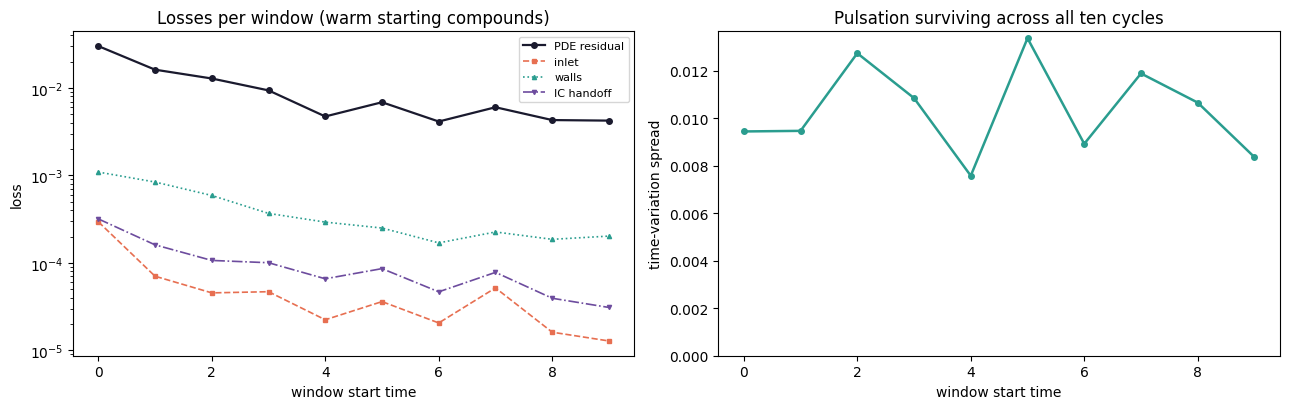

In [10]:
t0s=np.array(history["t0"])
INK="#1A1A2E"; CORAL="#E76F51"; TEAL="#2A9D8F"; PUR="#6D4C9E"
fig,ax=plt.subplots(1,2,figsize=(13,4.2))
ax[0].semilogy(t0s,history["pde"],'o-',color=INK,lw=1.6,ms=4,label='PDE residual')
ax[0].semilogy(t0s,history["inlet"],'s--',color=CORAL,lw=1.2,ms=3,label='inlet')
ax[0].semilogy(t0s,history["wall"],'^:',color=TEAL,lw=1.2,ms=3,label='walls')
ax[0].semilogy(t0s,history["ic"],'v-.',color=PUR,lw=1.2,ms=3,label='IC handoff')
ax[0].set_xlabel('window start time'); ax[0].set_ylabel('loss')
ax[0].set_title('Losses per window (warm starting compounds)'); ax[0].legend(fontsize=8)
ax[1].plot(t0s,history["timevar"],'o-',color=TEAL,lw=1.8,ms=4)
ax[1].set_xlabel('window start time'); ax[1].set_ylabel('time-variation spread')
ax[1].set_ylim(bottom=0)
ax[1].set_title('Pulsation surviving across all ten cycles')
plt.tight_layout(); plt.show()

## 14 — Results: the breathing bubble

The reattachment length is where wall shear changes sign on the floor. In a steady flow it is one number; here it **oscillates with every cycle**. Because the solution now lives in ten separate window models, we first need a helper that picks the right one for any time.

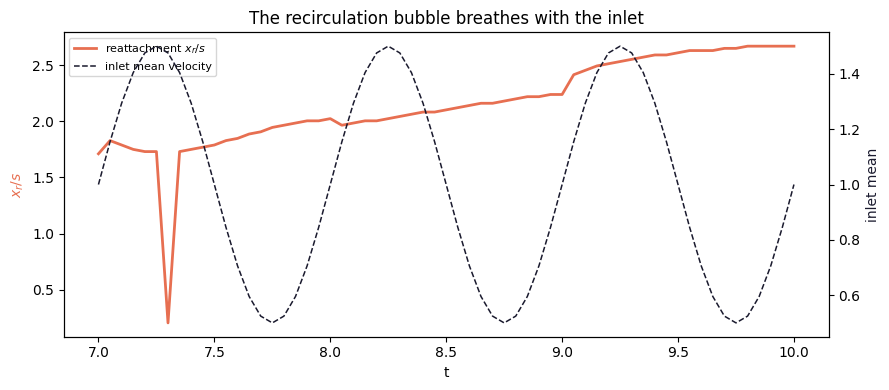

In [11]:
def model_for_time(t):
    "Return the window model that covers time t."
    for t0,t1,m in window_models:
        if t0 <= t <= t1: return m
    return window_models[-1][2]

def reattachment_at(t_val, n=500):
    "x where du/dy changes sign on the floor y=0, at time t_val."
    m = model_for_time(t_val)
    x = torch.linspace(0.05, 0.7*Lo, n, device=device).reshape(-1,1)
    y = torch.zeros_like(x).requires_grad_(True)
    t = torch.full_like(x, t_val)
    o = m(torch.cat([x,y,t],1)); u = o[:,0:1]
    du = torch.autograd.grad(u,y,torch.ones_like(u))[0].detach().flatten()
    xs = x.flatten(); sgn = torch.sign(du)
    idx = (sgn[:-1]<0)&(sgn[1:]>=0)
    return float(xs[int(idx.nonzero()[0])]) if idx.any() else float('nan')

# sample the last three cycles (early cycles carry the startup transient)
phases = np.linspace(T_END-3*T_PERIOD, T_END, 61)
xr      = [reattachment_at(float(t)) for t in phases]
mean_in = [1+AMP*math.sin(OMEGA*t) for t in phases]

fig,ax=plt.subplots(figsize=(9,4)); ax2=ax.twinx()
ax.plot(phases, xr, '-', color=CORAL, lw=2, label='reattachment $x_r/s$')
ax2.plot(phases, mean_in, '--', color=INK, lw=1.1, label='inlet mean velocity')
ax.set_xlabel('t'); ax.set_ylabel('$x_r/s$', color=CORAL); ax2.set_ylabel('inlet mean', color=INK)
ax.set_title('The recirculation bubble breathes with the inlet')
h1,l1=ax.get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels()
ax.legend(h1+h2,l1+l2,fontsize=8); plt.tight_layout(); plt.show()

## 15 — Animated GIFs of all ten seconds

The payoff. We sweep $t$ across the **entire horizon**, pulling each frame from whichever window owns that time, then write an animated GIF and display it inline.

saved bfs_speed_10s.gif  (all 10 seconds)


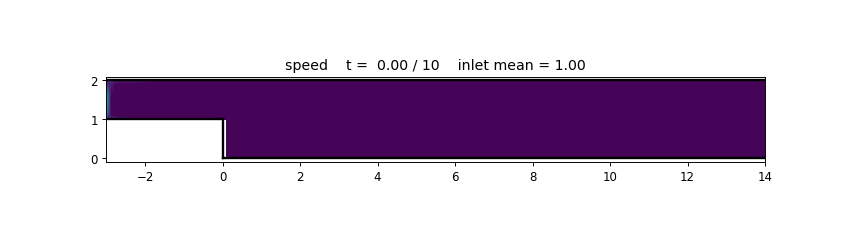

In [12]:
nx,ny = 160,44
xs = torch.linspace(-Li,Lo,nx,device=device); ys = torch.linspace(0,H,ny,device=device)
X,Y = torch.meshgrid(xs,ys,indexing='ij')
mask = inside_fluid(X,Y)
Xf, Yf = X.reshape(-1,1), Y.reshape(-1,1)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

@torch.no_grad()
def field_at(t, which='speed'):
    "Evaluate a field at time t using the correct window model."
    m = model_for_time(t)
    o = m(torch.cat([Xf,Yf,torch.full_like(Xf,t)],1))
    u,v = o[:,0:1], o[:,1:2]
    F = torch.sqrt(u**2+v**2) if which=='speed' else (u if which=='u' else v)
    F = F.reshape(nx,ny).clone(); F[~mask] = float('nan')
    return F.cpu().numpy()

def draw_walls(ax):
    ax.plot([-Li,Lo],[H,H],'k',lw=2); ax.plot([-Li,0],[s,s],'k',lw=2)
    ax.plot([0,0],[0,s],'k',lw=2);    ax.plot([0,Lo],[0,0],'k',lw=2)

def make_gif(which='speed', fname='bfs.gif', t_start=0.0, t_stop=None, n_frames=120, fps=15):
    t_stop = T_END if t_stop is None else t_stop
    frames = np.linspace(t_start, t_stop, n_frames)
    data   = [field_at(float(t), which) for t in frames]
    vmax   = float(np.nanmax([np.nanmax(np.abs(d)) for d in data]))
    vmin   = 0.0 if which=='speed' else -vmax
    cmap   = 'viridis' if which=='speed' else 'RdBu_r'
    fig,ax = plt.subplots(figsize=(10,2.8))
    def draw(i):
        ax.clear()
        ax.contourf(Xn,Yn,data[i],levels=30,cmap=cmap,vmin=vmin,vmax=vmax)
        draw_walls(ax)
        t = frames[i]
        ax.set_title(f"{which}    t = {t:5.2f} / {T_END:.0f}    "
                     f"inlet mean = {1+AMP*math.sin(OMEGA*t):.2f}")
        ax.set_aspect('equal'); ax.set_xlim(-Li,Lo); ax.set_ylim(-0.1,H+0.1)
        return []
    anim = FuncAnimation(fig, draw, frames=n_frames, blit=False)
    anim.save(fname, writer=PillowWriter(fps=fps), dpi=85)
    plt.close(fig)
    return fname

gif1 = make_gif('speed','bfs_speed_10s.gif', n_frames=120, fps=15)
print(f"saved {gif1}  (all {T_END:.0f} seconds)")
display(Image(filename=gif1))          # <-- plays inline

Horizontal velocity is more revealing still — **blue is reversed flow**, so you can watch the recirculation bubble physically grow and shrink behind the step, cycle after cycle.

saved bfs_u_10s.gif


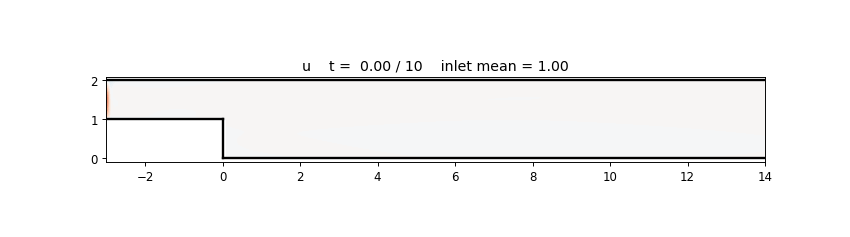

saved bfs_u_lastcycle.gif


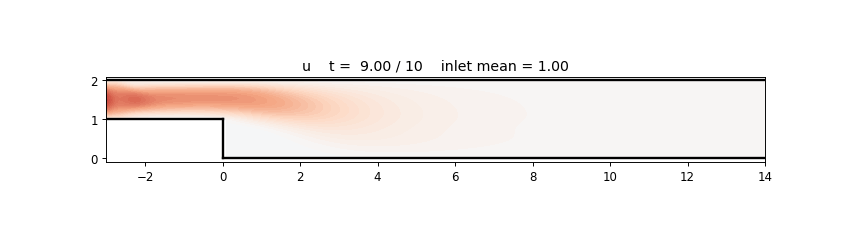

In [13]:
gif2 = make_gif('u','bfs_u_10s.gif', n_frames=120, fps=15)
print(f"saved {gif2}")
display(Image(filename=gif2))          # <-- plays inline

# A single cycle in slow motion, once the flow is fully established:
gif3 = make_gif('u','bfs_u_lastcycle.gif', t_start=T_END-T_PERIOD, t_stop=T_END,
                n_frames=40, fps=10)
print(f"saved {gif3}")
display(Image(filename=gif3))

# If a GIF shows as a static frame in your viewer, this fallback usually works:
# from IPython.display import HTML; import base64
# b64 = base64.b64encode(open(gif2,'rb').read()).decode()
# HTML(f'<img src="data:image/gif;base64,{b64}">')

## 16 — What You Have Built

You added the fourth coordinate — and then discovered that adding it is the easy part. Marching through it is the real work.

| Change | Cost |
|---|---|
| time as a network input | one extra input neuron |
| $u_t$, $v_t$ in the residual | one autograd slice, `grad(u,xyt)[:,2:3]` |
| initial condition | one extra loss term |
| **ten seconds of physics** | **ten windows, each handing its end state to the next** |

**Two lessons, and the second is the one to keep.**

*First*: this converged where vortex shedding doesn't, because the unsteadiness is **driven**. A pulsating inlet leaves no time-independent solution to hide in. Self-excited unsteadiness is structurally different — for flow past a cylinder the steady symmetric wake is *also* valid, so a forward PINN collapses onto it. That isn't a bug you can train away.

*Second*: **a plain PINN has no sense of time's arrow.** It optimizes $t=9$ with exactly as much urgency as $t=0$, which is fine over one cycle and disastrous over ten. Time-windowing restores causality by construction — and, pleasantly, makes the problem *cheaper*, since ten easy windows with warm starts beat one impossible slab.

**Diagnose it, always.** Keep the `timevar` habit: on any unsteady PINN, verify the solution actually varies in time before trusting a single plot. A converged loss on a silently-steady field is the most dangerous failure mode in this whole series.

---

### Failure modes to watch for

| Symptom | Cause | Fix |
|---|---|---|
| **`timevar` decays toward zero** | solution collapsing to a time-averaged steady field | check the inlet truly depends on `t`; raise `W_INLET`; confirm `u_t` is in the residual |
| **Oscillation fades at late times** (single-network run) | causality violation over a long horizon | this is exactly why we window — shorten `W_LEN` if it persists |
| Loss *jumps* at one window | the handoff degraded — that window started from a poor IC | give that window more iterations, or halve `W_LEN` |
| First cycle looks odd | startup transient from rest — this is **physical** | analyse the last cycles, not the first |
| `ic` term stays large | initial condition ignored | raise `W_IC`; add more `t=0` points |
| Memory grows with windows | ten models retained for animation | keep only every other model, or re-render GIFs per window |
| GIF renders but won't animate | viewer showing one frame | use the base64 HTML fallback above |

### Exercises

1. **Prove the causality problem.** Set `N_WINDOWS = 1` with `W_LEN = T_END` (one network, whole horizon) and compare `timevar` late in time against the windowed run. This is the controlled demonstration of *why* windowing exists.
2. **Window length sweep.** Try `W_LEN` of 0.5, 1.0, 2.0. Where is the sweet spot between per-window difficulty and number of handoffs?
3. **Change the pulsation.** Vary `AMP` (0.2 → 0.9) and the period. Does a faster pulse give the bubble time to fully form between beats?
4. **Kill the unsteadiness.** Set `AMP = 0`, retrain, confirm `timevar` → 0 and the steady solution returns — a controlled look at what "collapse to steady" really is.
5. **Womersley number.** The dimensionless group for pulsatile flow is $\alpha = s\sqrt{\omega/\nu}$. Compute it here, then sweep frequency: high $\alpha$ means the flow cannot keep up with the forcing.
6. **The honest one.** Raise `Re` past ~400 with a *steady* inlet and see whether the shear layer goes unsteady by itself. It won't — and understanding why is the whole of Section 2.
